# 平面 3R：操作空间控制实验室

## 目标
复用已有 RNEA 与正向动力学，依次完成末端定点、圆轨迹、零空间姿态实验。

**这是学习框架。四个核心公式尚未填写。** 未完成时只显示构型与待办提示，不产生闭环结果。
完整公式、单位与验收方法见 `docs/osc_learning.md`。

## 环境
在工程根目录安装 `python -m pip install -e '.[dev,notebook]'`，再启动 JupyterLab。
在 iPad 上连接 Jupyter 时，代码由服务器执行。此 Notebook 不要求桌面窗口或 GPU。

In [1]:
from pathlib import Path
import sys

# Support launching Jupyter from either the repository root or notebooks/.
root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'src/three_link_robot').is_dir()), None)
if root is None:
    raise RuntimeError('Open this notebook inside the three_link_robot checkout.')
for location in (root, root / 'src'):
    if str(location) not in sys.path:
        sys.path.insert(0, str(location))
%load_ext autoreload
%autoreload 2
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from examples.demo_osc import make_experiment, run_experiment, plot_experiment
from three_link_robot.operational_space import task_diagnostics, TaskSingularityError
from three_link_robot.kinematics import forward_kinematics
from three_link_robot.visualization import plot_robot, animate_robot
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.grid': True, 'grid.alpha': .25})
print('Project:', root.name)

No event loop hook running.
Project: three_link_robot


## 步骤
### 1. 选择实验与观察初始构型
`hold`：末端位置改变 2 cm；`circle`：半径 5 cm 的圆；`nullspace`：保持末端位置、调整姿态。
修改下面的 `TASK` 后，重新运行后续单元格。

Jacobian rank: 2
Singular values [m/rad]: [2.53449155 0.38234414]
Manipulability [(m/rad)^2]: 0.9690479880445066


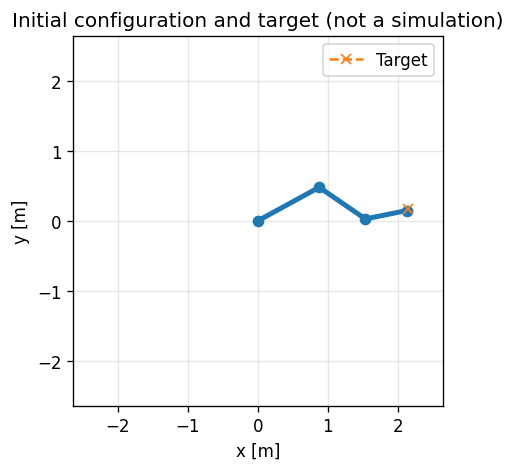

In [2]:
TASK = 'hold'  # 'hold', 'circle', or 'nullspace'
DURATION = 5.0
SAMPLES = 151
robot, initial, trajectory, controller = make_experiment(TASK)
diag = task_diagnostics(initial[:3], robot)
print('Jacobian rank:', diag['rank'])
print('Singular values [m/rad]:', diag['singular_values'])
print('Manipulability [(m/rad)^2]:', diag['manipulability'])
ax, _ = plot_robot(forward_kinematics(initial[:3], robot), reach=sum(robot.lengths))
ref_times = np.linspace(0, DURATION, SAMPLES)
ref_xy = np.array([trajectory(t).x for t in ref_times])
ax.plot(ref_xy[:, 0], ref_xy[:, 1], '--x', markevery=[0], label='Target')
ax.set_title('Initial configuration and target (not a simulation)')
ax.legend()
plt.show()

### 2. 检查公式并运行闭环
先完成 OSC-01～03，再尝试 `hold` / `circle`。`nullspace` 还需要 OSC-04。
只捕获明确的“未实现”和“奇异构型”异常；其他程序错误会直接显示。

In [3]:
data = None  # Prevent stale plots after a failed rerun.
try:
    controller(0., initial[:3], initial[3:], trajectory(0.), robot)
except NotImplementedError as error:
    print('尚未运行闭环：', error)
    print('请按 docs/osc_learning.md 填写对应公式，然后重新运行此单元格。')
except TaskSingularityError as error:
    print('构型检查未通过：', error)
else:
    data = run_experiment(TASK, duration=DURATION, samples=SAMPLES)
    print(f"Final position error: {data['error'][-1]:.6g} m")
    fig = plot_experiment(data)
    plt.show()

尚未运行闭环： OSC-01: implement jacobian_dot_times_dq in kinematics.py
请按 docs/osc_learning.md 填写对应公式，然后重新运行此单元格。


### 3. 可选：浏览器内播放动画
默认关闭，避免第一次学习时生成较大的 HTML。
这段动画仅在真实动力学闭环运行成功后生成。

In [4]:
SHOW_ANIMATION = False
if data is not None and SHOW_ANIMATION:
    time_step_ms = 1000 * (data['result'].t[1] - data['result'].t[0])
    figure, animation = animate_robot(data['points'], reach=sum(robot.lengths),
                                       interval_ms=time_step_ms)
    figure.axes[0].set_title('OSC closed-loop dynamics')
    display(HTML(animation.to_jshtml()))
    plt.close(figure)
elif data is None:
    print('没有闭环数据；不生成动画。')

没有闭环数据；不生成动画。


## 检查
在终端运行 `python -m pytest tests/test_osc.py -q -rs`。

- Jdot dq：是否与 Jacobian 沿 dq 方向的中心差分一致？
- Lambda：是否对称正定，且 `(J @ solve(M, J.T)) @ Lambda` 接近单位矩阵？
- 加速度：将控制力矩代入原有正动力学后，是否得到期望末端加速度？
- 零空间：是否满足 `J @ solve(M, N.T) = 0`？

**skipped 表示未完成，不是通过。** 这里只检查理想精确模型，尚未加入饱和、失配或接触。

## 下一步
先尝试把 Jdot dq 写出来并通过第一项检查。完成定点控制后再切换圆轨迹，最后研究零空间。
在零空间实验中观察 q 的变化，同时确认末端误差；不要要求任意姿态参考都能实现。